# Uçtan Uca Yapay Zeka Projesi: Veriden Tahmine
## Paylaşımlı Bisiklet Talebi Tahmini (Washington D.C., saatlik)

**Araçlar:** Python, Pandas, NumPy, Matplotlib, Seaborn, scikit-learn · **Ortam:** Google Colab / Jupyter

Bir bisiklet paylaşım sisteminde **belirli bir saatte kaç bisiklet kiralanacağını** tahmin ederiz. Çalışma gerçek bir veri seti üzerindedir ve basit bir model denemesinin ötesine geçer: zamana göre bölme, zaman serisine uygun çapraz doğrulama, 6 model, hiperparametre ayarı, iki senaryo (hava+takvim / + önceki talep), hata analizi ve belirsizlik aralığı içerir.

> **Colab:** `git clone https://github.com/b4tukk/bisiklet-talebi-tahmini` sonra `%cd bisiklet-talebi-tahmini`.

## Aşama 1 — Problem Tanımı
- **Problem:** Takvim bilgisi (ay, saat, hafta içi/sonu, tatil) ve hava durumu (sıcaklık, nem, rüzgâr, hava tipi) bilindiğinde, bir saatteki **toplam kiralama sayısını (`cnt`)** tahmin et.
- **Problem türü:** Regresyon (sayısal çıktı).
- **Kime fayda:** Sistem işletmecisi, istasyonlara bisiklet dağıtımını ve bakım saatlerini planlar; talebi önceden bilmek hem boş istasyon hem de atıl bisiklet maliyetini azaltır.
- **İki senaryo:** **A** = yalnızca hava + takvim (önceden bilinen; gerçek planlama senaryosu); **B** = A + bir saat önceki ve bir gün önceki talep (kısa vadeli; gerçek zamanlı bilgi gerektirir).
- **Başarı ölçütü:** MAE (kiralama/saat cinsinden ortalama hata), RMSE ve R²; ayrıca saat bazlı profil taban çizgisini aşıp aşmadığı.

## Aşama 2 — Veri ve Temizleme
**Kaynak:** Fanaee-T & Gama (2013), UCI *Bike Sharing Dataset* (Capital Bikeshare, Washington D.C., 2011–2012), 17.379 saatlik kayıt. Lisans: CC BY 4.0. Hava verileri UCI'de normalize edilmiştir (`temp×41`, `hum×100`, `windspeed×67`); gerçek birimlere çevrilir.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
sns.set_theme(style="whitegrid"); os.makedirs("figures", exist_ok=True); os.makedirs("models", exist_ok=True)
M = {}
df = pd.read_csv("data/hour.csv"); df["dteday"] = pd.to_datetime(df["dteday"]); df["zaman"] = df.dteday + pd.to_timedelta(df.hr, unit="h")
df = df.sort_values("zaman").reset_index(drop=True)
print(df.shape, df.zaman.min(), "→", df.zaman.max()); print("Eksik değer:", int(df.isnull().sum().sum()), "| Yinelenen:", int(df.duplicated().sum()))
tam = pd.date_range(df.zaman.min(), df.zaman.max(), freq="h"); print("Takvimde olması gereken saat:", len(tam), "| veride olan:", len(df), "| eksik saat:", len(tam) - len(df))
M.update(n=len(df), eksik_saat=len(tam) - len(df))
df.head(3)

(17379, 18) 2011-01-01 00:00:00 → 2012-12-31 23:00:00
Eksik değer: 0 | Yinelenen: 0
Takvimde olması gereken saat: 17544 | veride olan: 17379 | eksik saat: 165


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,zaman
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00


### Veri sözlüğü
| Sütun | Tip | Anlam |
|---|---|---|
| season, yr, mnth, hr | kategorik/sıralı | Mevsim (1–4), yıl (0=2011, 1=2012), ay, saat |
| holiday, weekday, workingday | ikili/sıralı | Resmî tatil, haftanın günü, iş günü |
| weathersit | sıralı (1–4) | 1 açık … 4 şiddetli yağış/kar |
| temp, atemp, hum, windspeed | sayısal | Sıcaklık, hissedilen, nem, rüzgâr (normalize) |
| casual, registered | sayısal | Kayıtsız / kayıtlı kullanıcı kiralamaları (**hedefin parçaları → özellik olarak kullanılmaz, sızıntı**) |
| **cnt** | **sayısal (hedef)** | Saatlik toplam kiralama |

**Temizleme kararları:** Eksik/yinelenen değer yok, ancak takvimde **eksik saatler** var (sistemin hiç kayıt olmadığı saatler). Bunlar için hedef uydurulmaz; gecikmeli (lag) özellikler yalnızca iki saat de mevcutsa hesaplanır. `casual` ve `registered` hedefi doğrudan toplamıyla verdiği için dışarıda bırakılır. `atemp`, `temp` ile neredeyse aynıdır (korelasyon > 0,98), doğrusal modellerde çoklu doğrusallık yaratmaması için çıkarılır.

In [2]:
df["temp_c"] = df.temp * 41; df["hum_pct"] = df.hum * 100; df["ruzgar_kmh"] = df.windspeed * 67
print("temp-atemp korelasyonu:", round(df.temp.corr(df.atemp), 3), "| hedef çarpıklığı:", round(df.cnt.skew(), 2), "| cnt min/medyan/max:", df.cnt.min(), df.cnt.median(), df.cnt.max())
s = df.set_index("zaman").cnt.reindex(tam)
df["lag1"] = df.zaman.map(s.shift(1)); df["lag24"] = df.zaman.map(s.shift(24))
print("Lag bulunamayan satır:", int(df[["lag1", "lag24"]].isnull().any(axis=1).sum()))
SEZON = df.groupby("mnth").season.agg(lambda x: x.mode().iloc[0]).to_dict(); print("Ay → mevsim:", SEZON)

temp-atemp korelasyonu: 0.988 | hedef çarpıklığı: 1.28 | cnt min/medyan/max: 1 142.0 977
Lag bulunamayan satır: 221
Ay → mevsim: {1: 1, 2: 1, 3: 1, 4: 2, 5: 2, 6: 2, 7: 3, 8: 3, 9: 3, 10: 4, 11: 4, 12: 4}


## Aşama 3 — Keşifçi Veri Analizi (EDA)

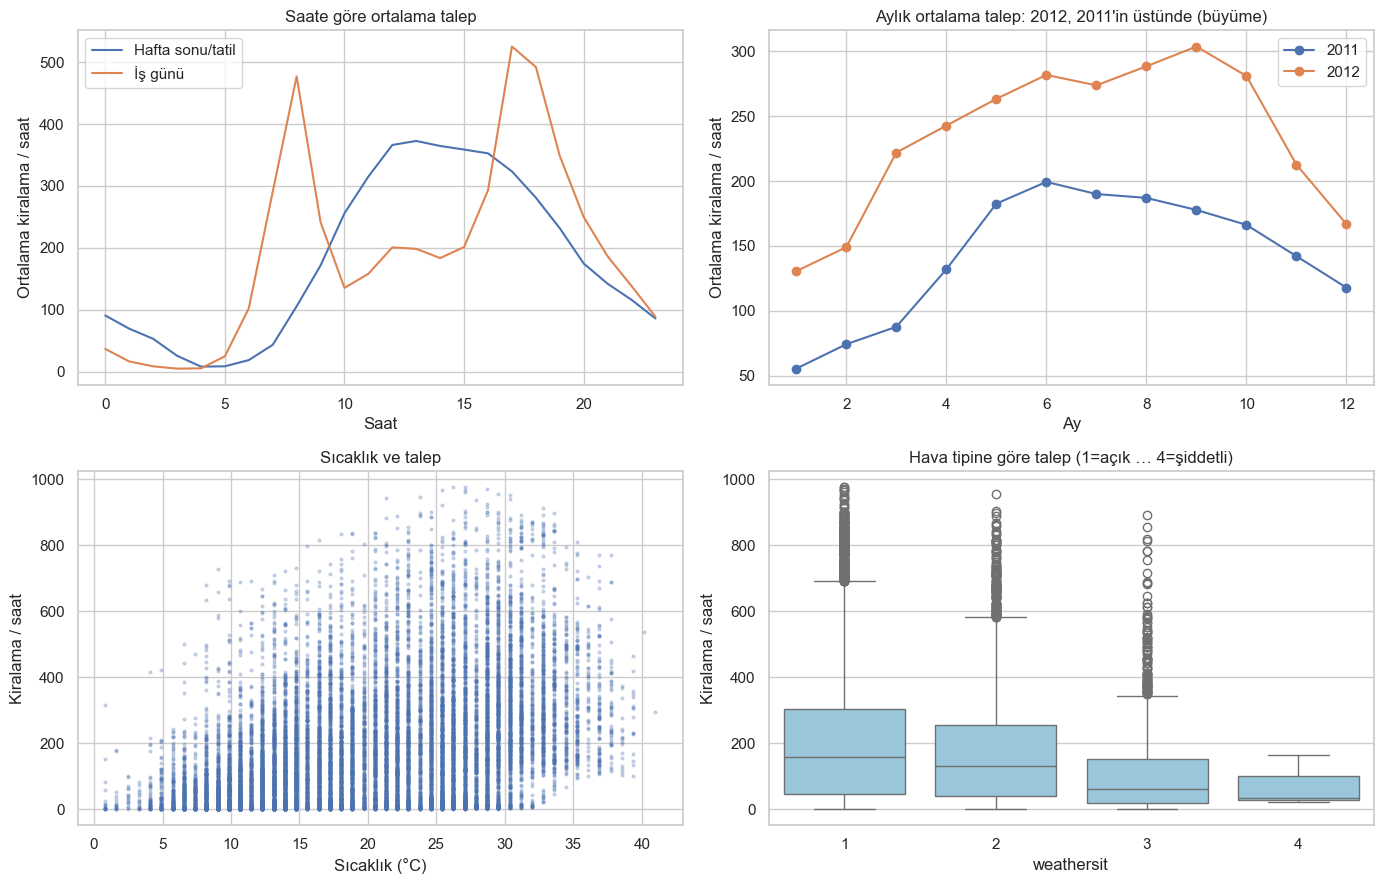

İş günü en yoğun saat: 17 → 525 | hafta sonu en yoğun saat: 13 → 373
Yıl ortalamaları: {0: 143.8, 1: 234.7}
Hava tipi ortalamaları: {1: 204.9, 2: 175.2, 3: 111.6, 4: 74.3}
cnt ile korelasyon: {'temp_c': 0.4, 'hum_pct': -0.32, 'ruzgar_kmh': 0.09, 'hr': 0.39, 'lag1': 0.84, 'lag24': 0.82}


In [3]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
sns.lineplot(data=df, x="hr", y="cnt", hue=df.workingday.map({0: "Hafta sonu/tatil", 1: "İş günü"}), estimator="mean", errorbar=None, ax=ax[0, 0]); ax[0, 0].set_title("Saate göre ortalama talep"); ax[0, 0].set_xlabel("Saat"); ax[0, 0].set_ylabel("Ortalama kiralama / saat"); ax[0, 0].legend(title="")
ay = df.groupby(["yr", "mnth"]).cnt.mean().unstack(0); ay.columns = ["2011", "2012"]; ay.plot(marker="o", ax=ax[0, 1]); ax[0, 1].set_title("Aylık ortalama talep: 2012, 2011'in üstünde (büyüme)"); ax[0, 1].set_xlabel("Ay"); ax[0, 1].set_ylabel("Ortalama kiralama / saat")
ax[1, 0].scatter(df.temp_c, df.cnt, s=4, alpha=.25); ax[1, 0].set_title("Sıcaklık ve talep"); ax[1, 0].set_xlabel("Sıcaklık (°C)"); ax[1, 0].set_ylabel("Kiralama / saat")
sns.boxplot(data=df, x="weathersit", y="cnt", ax=ax[1, 1], color="#8ecae6"); ax[1, 1].set_title("Hava tipine göre talep (1=açık … 4=şiddetli)"); ax[1, 1].set_xlabel("weathersit"); ax[1, 1].set_ylabel("Kiralama / saat")
plt.tight_layout(); plt.savefig("figures/eda.png", dpi=150); plt.show()
pik = df.groupby(["workingday", "hr"]).cnt.mean(); print("İş günü en yoğun saat:", int(pik[1].idxmax()), "→", round(pik[1].max()), "| hafta sonu en yoğun saat:", int(pik[0].idxmax()), "→", round(pik[0].max()))
print("Yıl ortalamaları:", df.groupby("yr").cnt.mean().round(1).to_dict()); print("Hava tipi ortalamaları:", df.groupby("weathersit").cnt.mean().round(1).to_dict())
print("cnt ile korelasyon:", df[["temp_c", "hum_pct", "ruzgar_kmh", "hr", "lag1", "lag24"]].corrwith(df.cnt).round(2).to_dict())
M["eda"] = dict(yil=df.groupby("yr").cnt.mean().round(1).to_dict(), hava=df.groupby("weathersit").cnt.mean().round(1).to_dict(), is_gunu_pik_saat=int(pik[1].idxmax()), hafta_sonu_pik_saat=int(pik[0].idxmax()), is_gunu_pik=float(pik[1].max()), hafta_sonu_pik=float(pik[0].max()))

### Keşif bulguları
1. **Talebin ritmi iş gününe bağlı:** iş günlerinde sabah (≈ 08) ve akşam (≈ 17–18) iki zirve (işe gidiş-dönüş), hafta sonları öğleye yayılan tek bir tepe var. Saat ve iş günü tek başına çok güçlü bilgi.
2. **Büyüme (trend):** 2012 talebi her ayda 2011'in üzerinde; model bu büyümeyi yakalamazsa gelecekte sistematik **eksik tahmin** yapar.
3. **Sıcaklık** talebi artırır, ama ilişki doğrusal değil (çok sıcakta düzleşir); **kötü hava** (yağış/kar) talebi belirgin biçimde düşürür.
4. Hedef **sağa çarpık** (çok sayıda düşük, az sayıda çok yüksek talep) → doğrusal modelde log dönüşümü, hata analizinde yüzdesel hata önemli.
5. `casual` + `registered = cnt` olduğu için bu iki sütun kullanılsaydı problem anlamsızca kolaylaşırdı (veri sızıntısı).

## Aşama 4 — Özellik Mühendisliği ve Zamana Göre Bölme
**Rastgele bölme yanlıştır:** komşu saatler çok benzer olduğundan, rastgele ayrılan test satırlarının "komşuları" eğitimde bulunur ve skor şişer. Bu yüzden **zamana göre bölünür**: **eğitim = 2011-01 … 2012-06, test = 2012-07 … 2012-12** (son 6 ay). Eğitim içinde model seçimi **TimeSeriesSplit** (5 katlı, hep geçmişle eğit-geleceği doğrula) ile yapılır.
Eklenen özellikler: `hr_sin`, `hr_cos` (saatin döngüselliği).

In [4]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df["hr_sin"] = np.sin(2 * np.pi * df.hr / 24); df["hr_cos"] = np.cos(2 * np.pi * df.hr / 24)
A = ["season", "yr", "mnth", "hr", "hr_sin", "hr_cos", "holiday", "weekday", "workingday", "weathersit", "temp_c", "hum_pct", "ruzgar_kmh"]
B = A + ["lag1", "lag24"]
KAT = ["season", "mnth", "hr", "weekday", "weathersit"]
egitim = df.zaman < "2012-07-01"; test = ~egitim
dfA, dfB = df, df.dropna(subset=["lag1", "lag24"])
def ayir(d, cols):
    e, t = d[d.zaman < "2012-07-01"], d[d.zaman >= "2012-07-01"]; return e[cols], e.cnt, t[cols], t.cnt, e, t
XtrA, ytrA, XteA, yteA, etrA, eteA = ayir(dfA, A); XtrB, ytrB, XteB, yteB, etrB, eteB = ayir(dfB, B)
print("A:", XtrA.shape, XteA.shape, "| B:", XtrB.shape, XteB.shape); M.update(n_tr=len(XtrA), n_te=len(XteA))
def metrik(y, p):
    p = np.clip(p, 0, None); return dict(MAE=mean_absolute_error(y, p), RMSE=float(np.sqrt(mean_squared_error(y, p))), R2=r2_score(y, p), RMSLE=float(np.sqrt(np.mean((np.log1p(p) - np.log1p(y)) ** 2))))
def lineer_on(cols):
    return ColumnTransformer([("k", OneHotEncoder(handle_unknown="ignore"), [c_ for c_ in KAT if c_ in cols]), ("s", StandardScaler(), [c_ for c_ in cols if c_ not in KAT])])

A: (13003, 13) (4376, 13) | B: (12813, 15) (4345, 15)


## Aşama 5 — Model Seçimi ve Karşılaştırma (Senaryo A)
Altı model, eğitim verisinde **5 katlı zaman serisi çapraz doğrulama** ile karşılaştırılır:
- **Saat profili taban çizgisi:** (iş günü, saat) bazında eğitim ortalaması; "akıllı olmayan" ama güçlü referans.
- **Doğrusal regresyon** (one-hot saat/gün + log hedef): yorumlanabilir temel model.
- **Karar ağacı** (derinlik 8), **Random Forest**, **Gradient Boosting (HistGB)**: doğrusal olmayan etkileşimleri (saat × iş günü × sıcaklık) yakalar.

In [5]:
class SaatProfili:
    """(workingday, hr) ortalaması. sklearn uyumlu minimal regresör."""
    def fit(self, X, y): self.t_ = pd.Series(np.asarray(y)).groupby([X["workingday"].values, X["hr"].values]).mean(); self.g_ = float(np.mean(y)); return self
    def predict(self, X): return np.array([self.t_.get((w, h), self.g_) for w, h in zip(X["workingday"], X["hr"])])
    def get_params(self, deep=True): return {}
    def set_params(self, **p): return self
def modeller(cols):
    return {
        "Saat profili (taban çizgisi)": SaatProfili(),
        "Doğrusal regresyon (log hedef)": Pipeline([("on", lineer_on(cols)), ("m", TransformedTargetRegressor(LinearRegression(), func=np.log1p, inverse_func=np.expm1))]),
        "Karar ağacı (derinlik 8)": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=0),
        "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=0),
        "Gradient Boosting (HistGB)": HistGradientBoostingRegressor(max_iter=300, learning_rate=.08, random_state=0),
    }
tscv = TimeSeriesSplit(5)
def cv_tablo(Xtr, ytr, cols):
    rows = []
    for ad, mdl in modeller(cols).items():
        mae, r2 = [], []
        for a, b in tscv.split(Xtr):
            mdl_ = modeller(cols)[ad].fit(Xtr.iloc[a], ytr.iloc[a]); p = np.clip(mdl_.predict(Xtr.iloc[b]), 0, None)
            mae.append(mean_absolute_error(ytr.iloc[b], p)); r2.append(r2_score(ytr.iloc[b], p))
        rows.append({"Model": ad, "CV MAE": np.mean(mae), "CV MAE std": np.std(mae), "CV R2": np.mean(r2)})
    return pd.DataFrame(rows).set_index("Model")
cvA = cv_tablo(XtrA, ytrA, A); display(cvA.round(3)); M["cv_A"] = cvA.round(4).reset_index().to_dict("records")

,CV MAE,CV MAE std,CV R2
Model,,,
Saat profili (taban çizgisi),79.467,29.843,0.491
Doğrusal regresyon (log hedef),74.651,22.011,0.511
Karar ağacı (derinlik 8),64.300,18.025,0.615
Random Forest,53.221,18.547,0.710
Gradient Boosting (HistGB),48.952,17.507,0.755


## Aşama 6 — Hiperparametre Ayarı ve Test Değerlendirmesi (Senaryo A)
Zaman serisi çapraz doğrulamasıyla Random Forest ve HistGB ayarlanır. En iyi model **ilk kez** test dönemi (2012 Temmuz–Aralık) üzerinde değerlendirilir.

In [6]:
gridler = {
    "Random Forest": (RandomForestRegressor(n_jobs=-1, random_state=0), {"n_estimators": [200], "min_samples_leaf": [2, 5], "max_features": [0.5, 1.0]}),
    "Gradient Boosting (HistGB)": (HistGradientBoostingRegressor(random_state=0), {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31], "max_iter": [300, 500], "l2_regularization": [0.0, 1.0]}),
}
ayarli = {}
for ad, (mdl, g) in gridler.items():
    gs = GridSearchCV(mdl, g, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(XtrA, ytrA); ayarli[ad] = gs.best_estimator_; print(f"{ad}: {gs.best_params_} | CV MAE = {-gs.best_score_:.2f}")
test_modelleri = {k: v.fit(XtrA, ytrA) for k, v in modeller(A).items() if k not in ayarli}; test_modelleri.update({k: v.fit(XtrA, ytrA) for k, v in ayarli.items()})
SONUC_A = {k: metrik(yteA, v.predict(XteA)) for k, v in test_modelleri.items()}
tA = pd.DataFrame(SONUC_A).T; display(tA.round(3)); M["test_A"] = tA.round(4).reset_index().rename(columns={"index": "Model"}).to_dict("records")
en_iyi_ad = tA.MAE.drop("Saat profili (taban çizgisi)").idxmin(); en_iyi = test_modelleri[en_iyi_ad]; M["secilen_A"] = en_iyi_ad
print("Seçilen model:", en_iyi_ad, "| taban çizgisine göre MAE iyileşmesi: %", round(100 * (1 - tA.loc[en_iyi_ad, "MAE"] / tA.loc["Saat profili (taban çizgisi)", "MAE"]), 1))

Random Forest: {'max_features': 1.0, 'min_samples_leaf': 2, 'n_estimators': 200} | CV MAE = 52.74


Gradient Boosting (HistGB): {'l2_regularization': 0.0, 'learning_rate': 0.1, 'max_iter': 500, 'max_leaf_nodes': 15} | CV MAE = 47.52


,MAE,RMSE,R2,RMSLE
Saat profili (taban çizgisi),107.210,150.349,0.532,0.600
Doğrusal regresyon (log hedef),86.075,124.964,0.676,0.601
Karar ağacı (derinlik 8),63.856,94.944,0.813,0.450
Random Forest,45.632,71.292,0.895,0.377
Gradient Boosting (HistGB),40.405,62.438,0.919,0.453


Seçilen model: Gradient Boosting (HistGB) | taban çizgisine göre MAE iyileşmesi: % 62.3


## Aşama 7 — Senaryo B (önceki talep bilgisiyle)
Bir saat önceki ve bir gün önceki gerçek talep (`lag1`, `lag24`) eklenir. Bu bilgi ancak sistem canlı çalışırken bilinir; planlama için senaryo A, kısa vadeli düzeltme için B anlamlıdır.

In [7]:
ayarliB = {k: type(v)(**v.get_params()).fit(XtrB, ytrB) for k, v in ayarli.items()}
SONUC_B = {k: metrik(yteB, v.predict(XteB)) for k, v in ayarliB.items()}
dB = pd.DataFrame(SONUC_B).T; display(dB.round(3)); M["test_B"] = dB.round(4).reset_index().rename(columns={"index": "Model"}).to_dict("records")
cmp = pd.DataFrame({"A MAE": tA.MAE.loc[dB.index], "B MAE": dB.MAE, "A R2": tA.R2.loc[dB.index], "B R2": dB.R2}).round(3); display(cmp)

,MAE,RMSE,R2,RMSLE
Random Forest,31.353,52.488,0.943,0.261
Gradient Boosting (HistGB),29.677,46.322,0.956,0.287


,A MAE,B MAE,A R2,B R2
Random Forest,45.632,31.353,0.895,0.943
Gradient Boosting (HistGB),40.405,29.677,0.919,0.956


## Aşama 8 — Hata Analizi ve Yorumlama

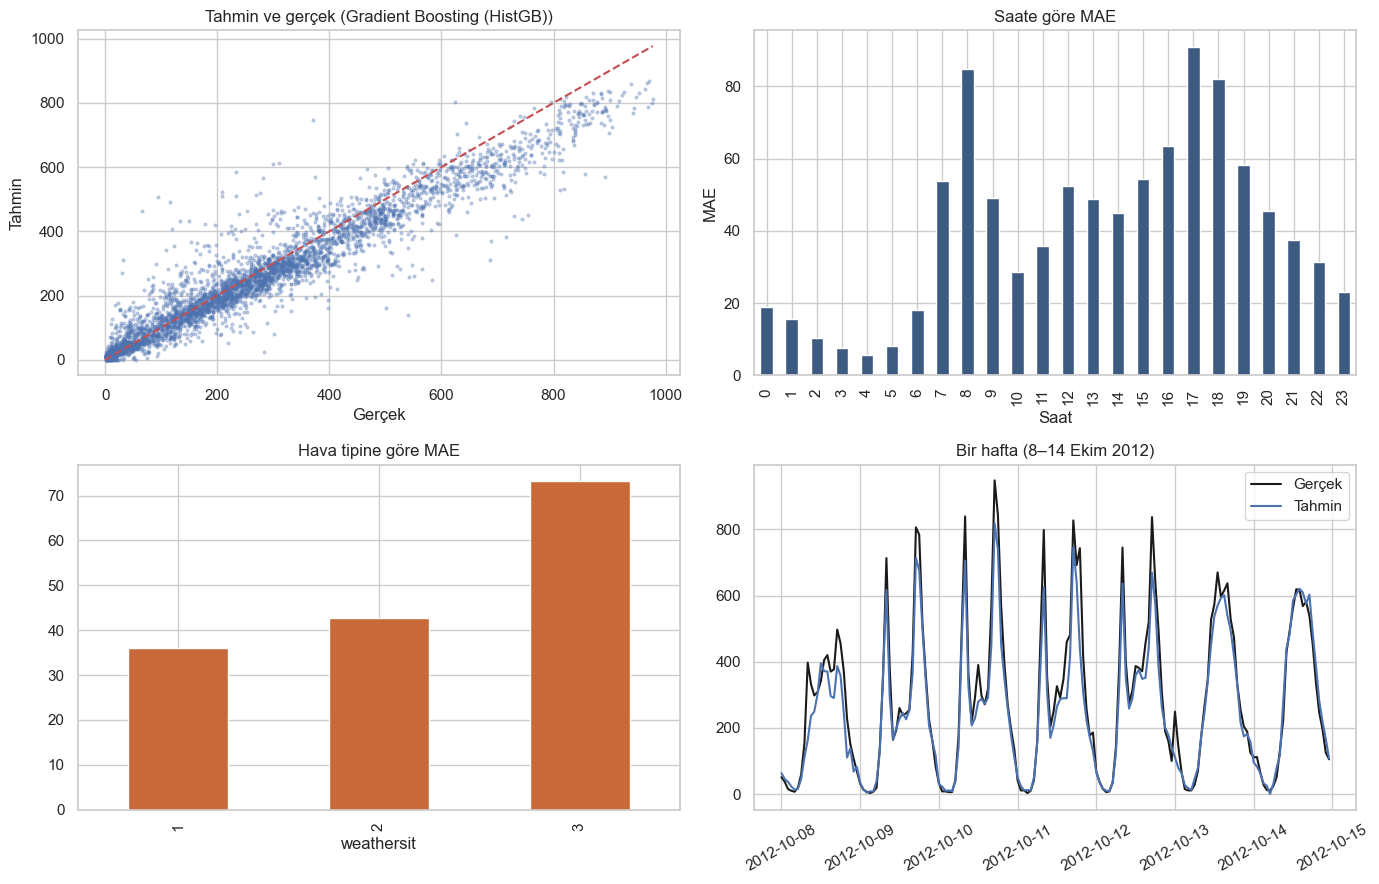

Ortalama yanlılık (tahmin-gerçek): -14.9 | MAE: 40.4 | yüksek talep (>400) MAE: 72.2 | düşük talep (<50) MAE: 12.2
Saat MAE (en kötü 3): {17: 90.9, 8: 84.8, 18: 82.1}
Hava MAE: {1: 36.0, 2: 42.6, 3: 73.2}
En büyük 5 hata:


,zaman,cnt,tahmin,weathersit,temp_c,hr,workingday,holiday
16454,2012-11-23 08:00:00,94,508.5,1,9.8,8,1,0
16190,2012-11-12 08:00:00,540,140.0,1,17.2,8,0,1
17196,2012-12-24 08:00:00,66,462.2,1,9.0,8,1,0
15890,2012-10-30 19:00:00,115,492.7,2,20.5,19,1,0
15253,2012-10-02 18:00:00,687,309.4,3,25.4,18,1,0


In [8]:
p = np.clip(en_iyi.predict(XteA), 0, None); hz = eteA.assign(tahmin=p, hata=p - eteA.cnt, mut=np.abs(p - eteA.cnt))
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
ax[0, 0].scatter(hz.cnt, hz.tahmin, s=4, alpha=.3); lim = [0, hz.cnt.max()]; ax[0, 0].plot(lim, lim, "r--"); ax[0, 0].set_title(f"Tahmin ve gerçek ({en_iyi_ad})"); ax[0, 0].set_xlabel("Gerçek"); ax[0, 0].set_ylabel("Tahmin")
hz.groupby("hr")[["mut"]].mean().plot.bar(ax=ax[0, 1], legend=False, color="#3d5a80"); ax[0, 1].set_title("Saate göre MAE"); ax[0, 1].set_xlabel("Saat"); ax[0, 1].set_ylabel("MAE")
hz.groupby("weathersit")["mut"].mean().plot.bar(ax=ax[1, 0], color="#c8693a"); ax[1, 0].set_title("Hava tipine göre MAE"); ax[1, 0].set_xlabel("weathersit")
g = hz.set_index("zaman").loc["2012-10-08":"2012-10-14"]; ax[1, 1].plot(g.index, g.cnt, "k", label="Gerçek"); ax[1, 1].plot(g.index, g.tahmin, label="Tahmin"); ax[1, 1].set_title("Bir hafta (8–14 Ekim 2012)"); ax[1, 1].legend(); ax[1, 1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figures/hata_analizi.png", dpi=150); plt.show()
yanlilik = float(hz.hata.mean()); print("Ortalama yanlılık (tahmin-gerçek):", round(yanlilik, 1), "| MAE:", round(hz.mut.mean(), 1), "| yüksek talep (>400) MAE:", round(hz[hz.cnt > 400].mut.mean(), 1), "| düşük talep (<50) MAE:", round(hz[hz.cnt < 50].mut.mean(), 1))
print("Saat MAE (en kötü 3):", hz.groupby("hr").mut.mean().sort_values(ascending=False).head(3).round(1).to_dict()); print("Hava MAE:", hz.groupby("weathersit").mut.mean().round(1).to_dict())
print("En büyük 5 hata:"); display(hz.reindex(hz.mut.sort_values(ascending=False).index).head(5)[["zaman", "cnt", "tahmin", "weathersit", "temp_c", "hr", "workingday", "holiday"]].round(1))
M["hata"] = dict(yanlilik=yanlilik, mae=float(hz.mut.mean()), yuksek_mae=float(hz[hz.cnt > 400].mut.mean()), dusuk_mae=float(hz[hz.cnt < 50].mut.mean()), saat_kotu=hz.groupby("hr").mut.mean().sort_values(ascending=False).head(3).round(1).to_dict(), hava_mae=hz.groupby("weathersit").mut.mean().round(1).to_dict(), en_buyuk=hz.reindex(hz.mut.sort_values(ascending=False).index).head(5).assign(zaman=lambda d: d.zaman.astype(str))[["zaman", "cnt", "tahmin"]].round(0).to_dict("records"))

{'hr': 76.77, 'hr_cos': 51.75, 'workingday': 38.25, 'hr_sin': 35.17, 'temp_c': 27.08, 'hum_pct': 9.89, 'weekday': 8.72, 'weathersit': 3.42}


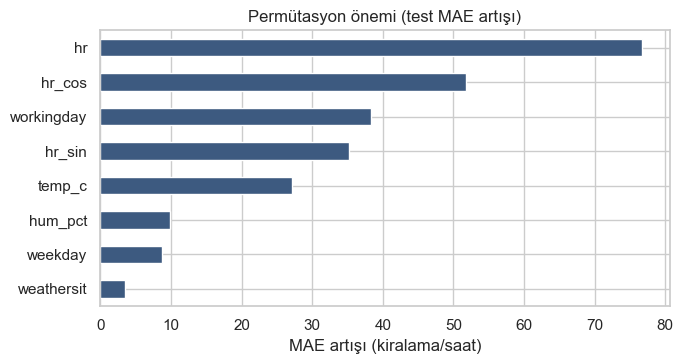

In [9]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(en_iyi, XteA, yteA, n_repeats=10, random_state=0, scoring="neg_mean_absolute_error", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=A).sort_values(ascending=False).head(8); print(imp.round(2).to_dict()); M["onem"] = imp.round(2).to_dict()
plt.figure(figsize=(7, 3.8)); imp[::-1].plot.barh(color="#3d5a80"); plt.title("Permütasyon önemi (test MAE artışı)"); plt.xlabel("MAE artışı (kiralama/saat)"); plt.tight_layout(); plt.savefig("figures/onem.png", dpi=150); plt.show()

## Aşama 9 — Modeli Kaydet ve Akıllı Tahmin Aracı
Final model eğitim + test dönemiyle yeniden eğitilir (tüm veri). Tahmin aralığı için, zaman serisi çapraz doğrulamasındaki **log-oran hatalarının %10–%90 dilimi** kullanılır (yaklaşık %80 aralık).

In [10]:
oof = []
for a, b in tscv.split(XtrA):
    mm = type(en_iyi)(**en_iyi.get_params()).fit(XtrA.iloc[a], ytrA.iloc[a]); pr = np.clip(mm.predict(XtrA.iloc[b]), 0, None); oof.append(np.log1p(ytrA.iloc[b].values) - np.log1p(pr))
oof = np.concatenate(oof); q10, q90 = float(np.quantile(oof, .10)), float(np.quantile(oof, .90))
final = type(en_iyi)(**en_iyi.get_params()).fit(df[A], df.cnt)
joblib.dump({"model": final, "kolonlar": A, "mevsim": SEZON, "q10": q10, "q90": q90}, "models/model.joblib"); print("log-hata q10/q90:", round(q10, 3), round(q90, 3))
# aralığın test dönemindeki kapsama oranı (kalibrasyon kontrolü)
lo, hi = np.expm1(np.log1p(p) + q10), np.expm1(np.log1p(p) + q90); kapsama = float(((eteA.cnt.values >= lo) & (eteA.cnt.values <= hi)).mean()); print("Test kapsama (hedef ≈ 0,80):", round(kapsama, 3)); M.update(q10=q10, q90=q90, kapsama=kapsama)
def tahmin_et(tarih, saat, sicaklik, nem=60, ruzgar=10, hava=1, tatil=0):
    t = pd.Timestamp(tarih); wd = (t.weekday() + 1) % 7              # UCI: 0=Pazar
    satir = pd.DataFrame([dict(season=SEZON[t.month], yr=int(t.year >= 2012), mnth=t.month, hr=saat, hr_sin=np.sin(2 * np.pi * saat / 24), hr_cos=np.cos(2 * np.pi * saat / 24), holiday=tatil, weekday=wd, workingday=int(wd not in (0, 6) and not tatil), weathersit=hava, temp_c=sicaklik, hum_pct=nem, ruzgar_kmh=ruzgar)])[A]
    mu_ = max(float(final.predict(satir)[0]), 0); a_, b_ = np.expm1(np.log1p(mu_) + q10), np.expm1(np.log1p(mu_) + q90)
    return f"{t.date()} saat {saat:02d}:00 için tahmini talep ≈ {mu_:.0f} bisiklet (yaklaşık %80 aralık: {a_:.0f}–{b_:.0f})."
def sor(metin, varsayilan):
    try: return type(varsayilan)(input(f"{metin} [{varsayilan}]: ") or varsayilan)
    except Exception: return varsayilan
ornekler = [tahmin_et("2012-10-16", 8, 17, 55, 8, 1), tahmin_et("2012-10-16", 8, 17, 90, 20, 3), tahmin_et("2012-10-20", 14, 24, 45, 6, 1), tahmin_et("2012-10-21", 3, 8, 70, 5, 1)]
for o in ornekler: print(o)
print(tahmin_et(sor("Tarih (YYYY-AA-GG)", "2012-10-16"), sor("Saat (0-23)", 18), sor("Sıcaklık °C", 18.0)))
M["ornekler"] = ornekler
json.dump(M, open("metrics.json", "w"), ensure_ascii=False, indent=1, default=float)

log-hata q10/q90: -0.703 0.632
Test kapsama (hedef ≈ 0,80): 0.905
2012-10-16 saat 08:00 için tahmini talep ≈ 789 bisiklet (yaklaşık %80 aralık: 390–1485).
2012-10-16 saat 08:00 için tahmini talep ≈ 328 bisiklet (yaklaşık %80 aralık: 162–617).
2012-10-20 saat 14:00 için tahmini talep ≈ 709 bisiklet (yaklaşık %80 aralık: 350–1335).
2012-10-21 saat 03:00 için tahmini talep ≈ 29 bisiklet (yaklaşık %80 aralık: 14–55).
2012-10-16 saat 18:00 için tahmini talep ≈ 700 bisiklet (yaklaşık %80 aralık: 346–1318).


## Sonuç
Yorum, rapor ve sunum dosyalarında (`Proje_Raporu.docx`, `Sunum.pptx`).